In [14]:
import sys
import os

sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..')))

import numpy as np
import pandas as pd

from utils.indicators import *
from utils.engine import *

import lightgbm as lgb
from sklearn.metrics import precision_score, recall_score, classification_report
import matplotlib.pyplot as plt

# ============================================================================
# CONFIG
# ============================================================================
LOOKAHEAD_SECONDS   = 240     # how far forward we check if the barrier was hit
BARRIER_MULTIPLIER  = 1.0     # profit/stop barrier = multiplier * horizon-scaled vol
RSI_FILTER_COLUMN   = 'rsi_14'
RSI_FILTER_THRESHOLD = 30
EPS                 = 1e-9    # guards against division by zero

# --- FIXED: Chronological Validation Settings ---
N_RANDOM_SAMPLES    = 15      # Number of sequential walk-forward folds to test
TEST_BLOCK_SIZE     = 10000   # Number of rows per test chunk
EMBARGO_SECONDS     = LOOKAHEAD_SECONDS  # Reserved for backward compatibility


# ============================================================================
# STEP 1 — Per-session feature pipeline
# ============================================================================
def load_and_build_state_space(orderbook_path, trades_path, session_id):
    df_orderbook = pd.read_csv(orderbook_path)
    df_trades = pd.read_csv(trades_path)

    df_orderbook['datetime'] = pd.to_datetime(df_orderbook['timestamp'], unit='ms')
    df_trades['datetime'] = pd.to_datetime(df_trades['timestamp'], unit='ms')

    df_orderbook = df_orderbook.set_index('datetime').sort_index()
    df_trades = df_trades.set_index('datetime').sort_index()

    df_orderbook['mid_price'] = (df_orderbook['bid_price'] + df_orderbook['ask_price']) / 2

    df_ob_1m = df_orderbook.resample('1min').agg({
        'mid_price': ['first', 'max', 'min', 'last'],
        'bid_price': 'last',
        'ask_price': 'last',
        'bid_amount': 'sum',
        'ask_amount': 'sum',
    })
    df_ob_1m.columns = ['open', 'high', 'low', 'close', 'bid_price', 'ask_price', 'bid_amount', 'ask_amount']
    df_ob_1m['spread'] = df_ob_1m['ask_price'] - df_ob_1m['bid_price']

    df_trades['buy_vol'] = df_trades['amount'].where(df_trades['side'] == 'buy', 0)
    df_trades['sell_vol'] = df_trades['amount'].where(df_trades['side'] == 'sell', 0)

    df_micro = df_trades.resample('1s').agg({
        'price': 'last',
        'buy_vol': 'sum',
        'sell_vol': 'sum'
    }).ffill()

    df_micro['micro_OFI'] = df_micro['buy_vol'] - df_micro['sell_vol']
    df_micro['micro_CVD'] = df_micro['micro_OFI'].rolling(10).sum()

    df_trades_1m = df_trades.resample('1min').agg({
        'price': ['first', 'max', 'min', 'last', 'count'],
        'amount': 'sum',
        'buy_vol': ['sum', 'max'],
        'sell_vol': ['sum', 'max']
    })
    df_trades_1m.columns = ['open', 'high', 'low', 'close', 'num_trades', 'volume',
                             'agg_buyer', 'largest_buyer', 'agg_seller', 'largest_seller']
    df_trades_1m = df_trades_1m.dropna(subset=['close'])

    df_price_1m = pd.DataFrame({
        'open': df_ob_1m['open'],
        'high': df_ob_1m['high'],
        'low': df_ob_1m['low'],
        'close': df_ob_1m['close'],
        'largest_buyer': df_trades_1m['largest_buyer'] * 100 / (df_trades_1m['volume'] + EPS),
        'largest_seller': df_trades_1m['largest_seller'] * 100 / (df_trades_1m['volume'] + EPS),
        'OFI_LOB': 100 * (df_ob_1m['bid_amount'] - df_ob_1m['ask_amount']) / (df_ob_1m['bid_amount'] + df_ob_1m['ask_amount'] + EPS),
        'OFI_AGG': 100 * (df_trades_1m['agg_buyer'] - df_trades_1m['agg_seller']) / (df_trades_1m['agg_buyer'] + df_trades_1m['agg_seller'] + EPS),
        'CVD_raw': calculate_cvd(df_trades_1m['agg_buyer'], df_trades_1m['agg_seller']),
        'candle_type': abs(df_ob_1m['close'] - df_ob_1m['open']) / (abs(df_ob_1m['high'] - df_ob_1m['low']) + EPS),
        'candle_size': (df_ob_1m['high'] - df_ob_1m['low']) / ((df_ob_1m['high'] - df_ob_1m['low']).rolling(14).mean() + EPS),
    })

    cvd_delta = df_price_1m['CVD_raw'].diff()
    df_price_1m['CVD_z'] = (cvd_delta - cvd_delta.rolling(60).mean()) / (cvd_delta.rolling(60).std() + EPS)
    df_price_1m = df_price_1m.drop(columns=['CVD_raw'])

    price_clean = np.asarray(df_price_1m['close'], dtype=float)
    diffs = np.diff(price_clean)

    def _pad_front(arr, target_len):
        out = np.full(target_len, np.nan)
        out[-len(arr):] = arr
        return out

    df_price_1m['rsi_2'] = _pad_front(get_wilders_rsi(diffs, 2), len(df_price_1m))
    rsi_14_raw = get_wilders_rsi(diffs, 14)
    df_price_1m['rsi_14'] = _pad_front(rsi_14_raw, len(df_price_1m))
    df_price_1m['sma_14'] = _pad_front(sma(rsi_14_raw, 14), len(df_price_1m))

    df_macro_shifted = df_price_1m.shift(1)
    df_state_space = df_micro.join(df_macro_shifted, how='left').ffill()
    df_state_space = df_state_space.dropna()
    df_state_space['session_id'] = session_id

    return df_state_space


# ============================================================================
# STEP 2 — Build combined state space from all sessions
# ============================================================================
session_0 = load_and_build_state_space(
    "./csv/BTCUSDT_orderbook.csv", "./csv/BTCUSDT_trades.csv", session_id=0
)
session_1 = load_and_build_state_space(
    "./csv/BTCUSDT_orderbook_2.csv", "./csv/BTCUSDT_trades_2.csv", session_id=1
)

df_state_space = pd.concat([session_0, session_1]).sort_index()


# ============================================================================
# STEP 3 — Barrier labeling
# ============================================================================
def add_barrier_labels(df, lookahead_seconds=LOOKAHEAD_SECONDS, barrier_mult=BARRIER_MULTIPLIER):
    labeled = []
    for _, g in df.groupby('session_id', sort=False):
        g = g.copy()
        ret_std_1s = g['price'].pct_change().rolling(window=100).std()
        horizon_std = ret_std_1s * np.sqrt(lookahead_seconds)

        g['profit_barrier'] = horizon_std * barrier_mult
        g['stop_barrier'] = horizon_std * barrier_mult

        forward_max = (g['price'].iloc[::-1]
                       .rolling(window=lookahead_seconds, min_periods=lookahead_seconds)
                       .max().iloc[::-1])
        forward_min = (g['price'].iloc[::-1]
                       .rolling(window=lookahead_seconds, min_periods=lookahead_seconds)
                       .min().iloc[::-1])

        mfe = (forward_max - g['price']) / g['price']
        mae = (g['price'] - forward_min) / g['price']

        valid = g['profit_barrier'].notna() & forward_max.notna() & forward_min.notna()
        g['target'] = np.nan
        g.loc[valid, 'target'] = np.where(
            (mfe[valid] >= g.loc[valid, 'profit_barrier']) & (mae[valid] < g.loc[valid, 'stop_barrier']),
            1, 0
        )
        labeled.append(g)

    out = pd.concat(labeled)
    out = out.dropna(subset=['target'])
    out['target'] = out['target'].astype(int)
    return out

df_state_space = add_barrier_labels(df_state_space)

df_training_zone = df_state_space[df_state_space[RSI_FILTER_COLUMN] < RSI_FILTER_THRESHOLD]
print(f"Total rows in hunting zone: {len(df_training_zone)}")


# ============================================================================
# STEP 4 — Features / target
# ============================================================================
drop_cols = ['target', 'price', 'open', 'high', 'low', 'close',
             'profit_barrier', 'stop_barrier', 'session_id']
features = [c for c in df_training_zone.columns if c not in drop_cols]

X = df_training_zone[features]
y = df_training_zone['target']


# ============================================================================
# STEP 5 — FIXED: Purged Chronological Walk-Forward Splitting
# ============================================================================
def purged_chronological_splits(index, n_samples, block_size, horizon_seconds, embargo_seconds=0):
    """
    FIXED: Replaced random blocks with sequential, forward-moving validation windows.
    Training arrays are strictly isolated BEFORE the testing segment.
    Labels are purged at the train-test boundary to guarantee zero predictive leakage.
    """
    n = len(index)
    horizon = pd.Timedelta(seconds=horizon_seconds)
    
    # Reserve a baseline chronological buffer for initial training data (e.g., 35% of total rows)
    min_initial_train = int(n * 0.35)
    available_test_run = n - min_initial_train - block_size
    
    if available_test_run <= 0:
        raise ValueError("The dataset length is too narrow for this test configuration block size.")
        
    # Chronologically distribute start coordinates for test windows
    step_intervals = available_test_run // n_samples
    
    for fold in range(n_samples):
        start_idx = min_initial_train + (fold * step_intervals)
        test_idx = np.arange(start_idx, start_idx + block_size)
        
        test_start_time = index[test_idx[0]]
        
        # Training array index boundaries are structurally pinned BEFORE the test window
        possible_train_idx = np.arange(0, start_idx)
        train_times = index[possible_train_idx]
        
        # Purge execution: Drop features whose label calculation window intersects test execution boundaries
        purge_mask = (train_times + horizon >= test_start_time)
        train_idx = possible_train_idx[~purge_mask]
        
        n_purged = len(possible_train_idx) - len(train_idx)
        yield train_idx, test_idx, n_purged

# Assign structural chronological execution generator
splitter = purged_chronological_splits(
    X.index, 
    n_samples=N_RANDOM_SAMPLES, 
    block_size=TEST_BLOCK_SIZE,
    horizon_seconds=LOOKAHEAD_SECONDS,
    embargo_seconds=EMBARGO_SECONDS
)

print(f"\n--- Starting {N_RANDOM_SAMPLES} Chronological Walk-Forward Validation Folds (Size: {TEST_BLOCK_SIZE}) ---")

# Setup matrix to track metrics at different thresholds per fold
thresholds_to_track = np.arange(0.50, 0.96, 0.05)
fold_metrics = {t: {'precisions': [], 'trades': []} for t in thresholds_to_track}
fold_importances = []

for fold, (train_idx, test_idx, n_purged) in enumerate(splitter, start=1):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    if len(X_train) == 0 or y_train.nunique() < 2:
        print(f"Fold {fold} | skipped — invalid training data distribution.")
        continue

    neg_pos_ratio = sum(y_train == 0) / max(sum(y_train == 1), 1)

    clf = lgb.LGBMClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=5,
        num_leaves=31,
        scale_pos_weight=neg_pos_ratio,
        random_state=42,
        n_jobs=-1,
        verbose=-1
    )

    clf.fit(X_train, y_train)
    y_proba = clf.predict_proba(X_test)[:, 1]
    
    # Calculate performance for THIS specific block across all thresholds
    for t in thresholds_to_track:
        preds = (y_proba >= t).astype(int)
        prec = precision_score(y_test, preds, zero_division=0)
        num_trades = int(preds.sum())
        
        # Only record precision if trades actually fired (avoiding 0% dragging the mean down)
        if num_trades > 0:
            fold_metrics[t]['precisions'].append(prec)
        fold_metrics[t]['trades'].append(num_trades)

    fold_importances.append(clf.feature_importances_)
    print(f"Fold {fold:02d} | Train Rows: {len(X_train):<6} | Tested on forward {TEST_BLOCK_SIZE} rows. Purged: {n_purged}")


# ============================================================================
# STEP 6 — Threshold Fluctuation Reporting
# ============================================================================
print("\n--- Edge Stability Across Chronological Windows (Honest Analysis) ---")
print("Without lookahead leakage, this metric accurately reflects real-world expectation.")
print("-" * 75)
print(f"{'Threshold':<10} | {'Mean Prec':<11} | {'Std Dev (Fluct)':<16} | {'Avg Trades per Block'}")
print("-" * 75)

for t in thresholds_to_track:
    prec_array = np.array(fold_metrics[t]['precisions'])
    trades_array = np.array(fold_metrics[t]['trades'])
    
    if len(prec_array) > 0:
        mean_prec = np.mean(prec_array)
        std_prec = np.std(prec_array)
        mean_trades = np.mean(trades_array)
        
        print(f">= {t*100:>4.1f}%   | {mean_prec:>9.2%}   | ± {std_prec:<13.2%} | {mean_trades:>6.1f}")
    else:
        print(f">= {t*100:>4.1f}%   | No trades fired in any test block.")

print("-" * 75)

# Feature Importance Stability
if fold_importances:
    imp_df = pd.DataFrame(fold_importances, columns=features)
    imp_summary = pd.DataFrame({
        'mean_importance': imp_df.mean(),
        'std_importance': imp_df.std()
    }).sort_values('mean_importance', ascending=False)

    print("\n--- Top 10 Feature Importance Stability ---")
    print(imp_summary.head(10))

Total rows in hunting zone: 193740

--- Starting 15 Chronological Walk-Forward Validation Folds (Size: 10000) ---
Fold 01 | Train Rows: 67569  | Tested on forward 10000 rows. Purged: 240
Fold 02 | Train Rows: 75297  | Tested on forward 10000 rows. Purged: 240
Fold 03 | Train Rows: 83025  | Tested on forward 10000 rows. Purged: 240
Fold 04 | Train Rows: 90753  | Tested on forward 10000 rows. Purged: 240
Fold 05 | Train Rows: 98481  | Tested on forward 10000 rows. Purged: 240
Fold 06 | Train Rows: 106209 | Tested on forward 10000 rows. Purged: 240
Fold 07 | Train Rows: 113937 | Tested on forward 10000 rows. Purged: 240
Fold 08 | Train Rows: 121800 | Tested on forward 10000 rows. Purged: 105
Fold 09 | Train Rows: 129393 | Tested on forward 10000 rows. Purged: 240
Fold 10 | Train Rows: 137121 | Tested on forward 10000 rows. Purged: 240
Fold 11 | Train Rows: 144849 | Tested on forward 10000 rows. Purged: 240
Fold 12 | Train Rows: 152577 | Tested on forward 10000 rows. Purged: 240
Fold 13 | 

# Patch for ml-state code by AI
Integrate random splitting of data to ensure the code truly works and there is no overfitting problem. How we test the stability of machine learning algo:
- Run on large-sample sized splits (20k). Measure Mean Precision of trades across sample size then get Std Dev to get flucutation of performance in machine learning algo.
- Deduce based on expectancy formula if strtaegy is profitable or not. Further validation by changing sample size, switching tickers, etc.

# Conclusion (20k samples)
![performance](./image/img_12.png)

With condition 2RR, trading on 85%-95% shows a very stable edge.
- Average no of trades: 5.67 trades per hour
- 85.0%: 52.36% * 2RR - 47.64% = 0.5708RR
- Worst condition: (52.36% - 22.98%) * 2RR - (100% - 52.36% + 22.98%) = 0.5876 - 0.7062 = -0.1186RR
- Using assumption that it is a normal distribution, 65% of the time, the model performs reasonably well and generally has a positive expectancy. However there is a 5% chance that the model experiences severe underperformance (2x stdev)

# Conclusion (10k samples split)
![Performance](./image/img_13.png)

With condition 2RR, trading on 85%-95% shows a very stable edge.
- Average no of trades: 3.348 trades per hour
- 85.0%: 62.37% * 2RR - 37.63% = 0.8711RR
- Worst condition: (62.37% - 21.44%) * 2RR - (100% - 62.37% + 21.44%) = 0.8186 - 0.5907 = 0.2279RR
- Using assumption that it is a normal distribution, 65% of the time, the model performs exceptionally well and generally has a positive expectancy even when the market is 1stdev worse. For the strategy to hit breakeven, it should hit the 1.38x stdev area.

Nevermind ignore this conclusion for now. realized lookahead bias

Training on 154992 rows, Testing on 38748 rows...

 📈 STRATEGY PERFORMANCE SUMMARY (OUT OF SAMPLE)
Total Trades Taken : 2007
Win Rate           : 64.08%
Total Net Return   : 84.92% (Fixed size)
Max Drawdown       : -20.39%
Daily Sharpe Ratio : 22.09


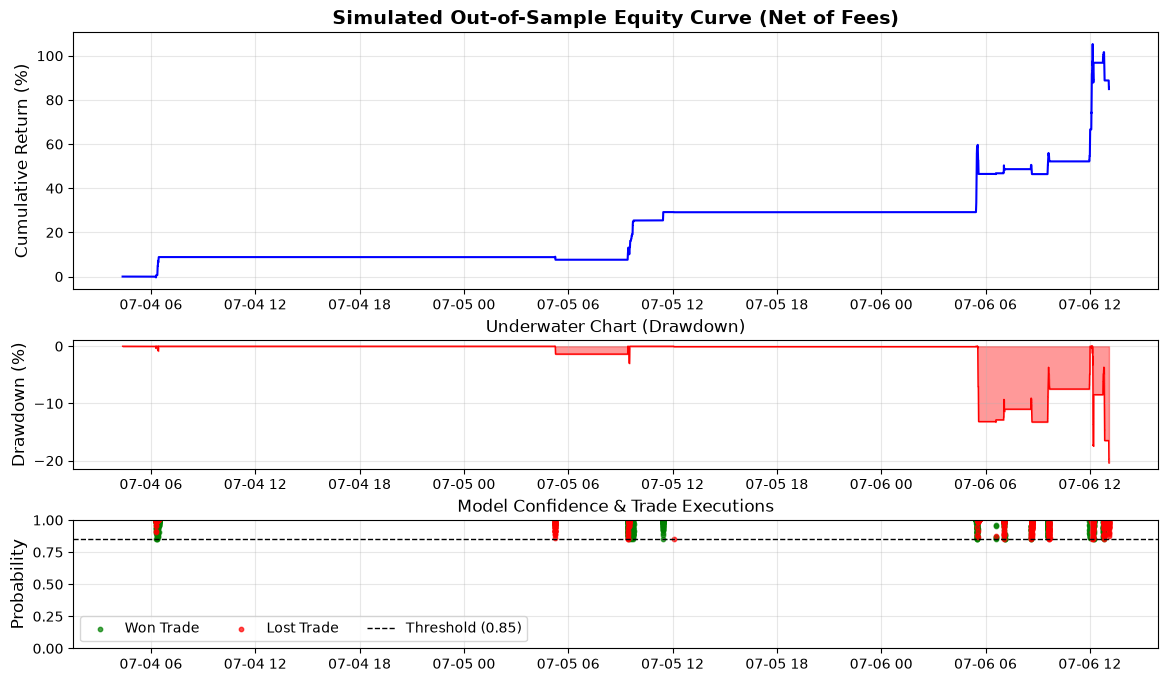

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import lightgbm as lgb
from matplotlib.gridspec import GridSpec

# ============================================================================
# CONFIG FOR BACKTEST
# ============================================================================
CONFIDENCE_THRESHOLD = 0.85  # Model probability required to fire a trade
FEE_BPS = 0.0                # Assumed execution fee in basis points (e.g., Binance taker)
TRAIN_TEST_SPLIT = 0.80      # 80% train, 20% chronological test

fee_pct = FEE_BPS / 10000

# ============================================================================
# STEP 1 — Chronological Split
# ============================================================================
# Ensure data is sorted chronologically
df_bt = df_training_zone.sort_index().copy()

split_idx = int(len(df_bt) * TRAIN_TEST_SPLIT)
train_data = df_bt.iloc[:split_idx]
test_data = df_bt.iloc[split_idx:].copy()

X_train_bt = train_data[features]
y_train_bt = train_data['target']
X_test_bt = test_data[features]
y_test_bt = test_data['target']

# ============================================================================
# STEP 2 — Train Final Model
# ============================================================================
neg_pos_ratio = sum(y_train_bt == 0) / max(sum(y_train_bt == 1), 1)

clf_bt = lgb.LGBMClassifier(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=5,
    num_leaves=31,
    scale_pos_weight=neg_pos_ratio,
    random_state=42,
    n_jobs=-1,
    verbose=-1
)

print(f"Training on {len(X_train_bt)} rows, Testing on {len(X_test_bt)} rows...")
clf_bt.fit(X_train_bt, y_train_bt)

# ============================================================================
# STEP 3 — Generate Signals & Vectorized Backtest
# ============================================================================
test_data['prob'] = clf_bt.predict_proba(X_test_bt)[:, 1]
test_data['signal'] = (test_data['prob'] >= CONFIDENCE_THRESHOLD).astype(int)

# Isolate trades
test_data['trade_return'] = 0.0

traded_mask = test_data['signal'] == 1
won_mask = traded_mask & (test_data['target'] == 0)
lost_mask = traded_mask & (test_data['target'] == 1)

# Apply returns (Profit barrier if won, Stop barrier if lost, minus fees)
test_data.loc[won_mask, 'trade_return'] = test_data.loc[won_mask, 'profit_barrier'] - fee_pct
test_data.loc[lost_mask, 'trade_return'] = -test_data.loc[lost_mask, 'stop_barrier'] - fee_pct

# Calculate Equity Curve (Assuming non-compounding, fixed size allocation per trade)
test_data['equity_curve'] = test_data['trade_return'].cumsum()

# ============================================================================
# STEP 4 — Performance Metrics
# ============================================================================
total_trades = traded_mask.sum()

if total_trades > 0:
    winning_trades = won_mask.sum()
    win_rate = winning_trades / total_trades
    
    # Max Drawdown Calculation
    running_max = test_data['equity_curve'].cummax()
    drawdown = test_data['equity_curve'] - running_max
    max_drawdown = drawdown.min()
    
    # Annualized Sharpe Ratio (Based on daily returns)
    daily_returns = test_data['trade_return'].resample('D').sum()
    
    # Protect against zero division if variance is zero
    daily_std = daily_returns.std()
    if daily_std > 0:
        # 365 days for crypto
        sharpe_ratio = (daily_returns.mean() / daily_std) * np.sqrt(365)
    else:
        sharpe_ratio = 0.0

    total_return_pct = test_data['equity_curve'].iloc[-1]
else:
    win_rate = 0.0
    max_drawdown = 0.0
    sharpe_ratio = 0.0
    total_return_pct = 0.0

print("\n" + "="*50)
print(" 📈 STRATEGY PERFORMANCE SUMMARY (OUT OF SAMPLE)")
print("="*50)
print(f"Total Trades Taken : {total_trades}")
print(f"Win Rate           : {win_rate:.2%}")
print(f"Total Net Return   : {total_return_pct:.2%} (Fixed size)")
print(f"Max Drawdown       : {max_drawdown:.2%}")
print(f"Daily Sharpe Ratio : {sharpe_ratio:.2f}")
print("="*50)

# ============================================================================
# STEP 5 — Visualization
# ============================================================================
if total_trades > 0:
    fig = plt.figure(figsize=(14, 8))
    gs = GridSpec(3, 1, height_ratios=[2, 1, 1], hspace=0.3)

    # 1. Equity Curve
    ax1 = fig.add_subplot(gs[0])
    ax1.plot(test_data.index, test_data['equity_curve'] * 100, color='blue', linewidth=1.5)
    ax1.set_title("Simulated Out-of-Sample Equity Curve (Net of Fees)", fontsize=14, fontweight='bold')
    ax1.set_ylabel("Cumulative Return (%)", fontsize=12)
    ax1.grid(True, alpha=0.3)

    # 2. Drawdown Chart
    ax2 = fig.add_subplot(gs[1], sharex=ax1)
    ax2.fill_between(test_data.index, drawdown * 100, 0, color='red', alpha=0.4)
    ax2.plot(test_data.index, drawdown * 100, color='red', linewidth=1)
    ax2.set_title("Underwater Chart (Drawdown)", fontsize=12)
    ax2.set_ylabel("Drawdown (%)", fontsize=12)
    ax2.grid(True, alpha=0.3)

    # 3. Model Probabilities & Trade Triggers
    ax3 = fig.add_subplot(gs[2], sharex=ax1)
    ax3.scatter(test_data[won_mask].index, test_data[won_mask]['prob'], color='green', s=10, label='Won Trade', alpha=0.7)
    ax3.scatter(test_data[lost_mask].index, test_data[lost_mask]['prob'], color='red', s=10, label='Lost Trade', alpha=0.7)
    ax3.axhline(CONFIDENCE_THRESHOLD, color='black', linestyle='--', linewidth=1, label=f'Threshold ({CONFIDENCE_THRESHOLD})')
    ax3.set_title("Model Confidence & Trade Executions", fontsize=12)
    ax3.set_ylabel("Probability", fontsize=12)
    ax3.set_ylim(0, 1)
    ax3.legend(loc='lower left', ncol=3)
    ax3.grid(True, alpha=0.3)

    plt.show()
else:
    print("No trades were executed. Try lowering your CONFIDENCE_THRESHOLD.")